## Student Performance Indicator


#### Life cycle of Machine learning Project

- Understanding the Problem Statement
- Data Collection
- Data Checks to perform
- Exploratory data analysis
- Data Pre-Processing
- Model Training
- Choose best model

### 1) Problem statement
- This project understands how the student's performance (test scores) is affected by other variables such as Gender, Ethnicity, Parental level of education, Lunch and Test preparation course.


### 2) Data Collection
- Dataset Source - https://www.kaggle.com/datasets/spscientist/students-performance-in-exams?datasetId=74977
- The data consists of 8 column and 1000 rows.

## **1. Environment Setup**

In [1]:
# Warning management and configuration
import warnings
warnings.filterwarnings('ignore')

# Data manipulation and numerical operations
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Enable inline plotting for Jupyter Notebooks
%matplotlib inline

## **2. Exploratoty Data Analysis**

### **2.1. Data Loading**

In [2]:
df = pd.read_csv('data/stud.csv')

### **2.2. Initial Data Inspection**

Before diving into visualizations, we need to inspect the data quality and ensure everything is clean. On that note, we'll check:

- Dataset structure
- Data types
- Missing values
- Unique values/categories per column
- Duplicate rows
- Dataset statistics

In [3]:
# Preview of the first observations
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [4]:
# Shape of the dataset
df.shape

(1000, 8)

In [5]:
# Basic information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race_ethnicity               1000 non-null   str  
 2   parental_level_of_education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test_preparation_course      1000 non-null   str  
 5   math_score                   1000 non-null   int64
 6   reading_score                1000 non-null   int64
 7   writing_score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


In [6]:
# Display unique categories for each categorical feature
print("Categories in 'gender':", df['gender'].unique().tolist())
print("Categories in 'race_ethnicity':", df['race_ethnicity'].unique().tolist())
print("Categories in 'parental_level_of_education':", df['parental_level_of_education'].unique().tolist())
print("Categories in 'lunch':", df['lunch'].unique().tolist())
print("Categories in 'test_preparation_course':", df['test_preparation_course'].unique().tolist())

Categories in 'gender': ['female', 'male']
Categories in 'race_ethnicity': ['group B', 'group C', 'group A', 'group D', 'group E']
Categories in 'parental_level_of_education': ["bachelor's degree", 'some college', "master's degree", "associate's degree", 'high school', 'some high school']
Categories in 'lunch': ['standard', 'free/reduced']
Categories in 'test_preparation_course': ['none', 'completed']


### **Dataset Information**

Dataset structure and features:

- `gender`: Student's gender (`male` / `female`).
- `race_ethnicity`: Ethnic group (`Group A`, `Group B`, `Group C`, `Group D`, `Group E`).
- `parental_level_of_education`: Parents' highest education level (`bachelor's degree`, `some college`, `master's degree`, `associate's degree`, `high school`, `some high school`).
- `lunch`: Type of lunch before the test (`standard` or `free/reduced`).
- `test_preparation_course`: Whether the student completed a prep course (`completed` or `none`).
- `math_score`: Score achieved in math.
- `reading_score`: Score achieved in reading.
- `writing_score`: Score achieved in writing.

### *Key findings*
As of **data types**, categorical features are stored cleanly as strings, while scores (`math`, `reading`, `writing`, `total score`, and `average`) are correctly typed as numeric (`int64` and `float64`). 

Also, we see there are no missing values, so we can proceed with our duplicates analysis.

### **Checking Duplicates**

In [7]:
# Check for duplicate rows in the dataset
print(f"Number of duplicate rows: {df.duplicated().sum()}")

Number of duplicate rows: 0


No duplicate rows found. Every record in our dataset is completely unique, so we don't need to drop anything.

### **Checking the number of unique values of each column**

In [8]:
# Check the number of unique values for each column
df.nunique()

gender                          2
race_ethnicity                  5
parental_level_of_education     6
lunch                           2
test_preparation_course         2
math_score                     81
reading_score                  72
writing_score                  77
dtype: int64

Inspected categorical features to confirm consistent labeling and verify that categories match expected values without hidden typos or formatting issues.

### **Checking statistics of dataset**

In [9]:
df.describe()

,math_score,reading_score,writing_score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


### *Key Findings*
- **Score Distribution**: Mean scores across all three subjects remain closely aligned around 66–69 points, with reading and writing showing slightly higher averages than mathematics.
- **Spread and Variability**: Standard deviations remain consistent near 14–15 points, indicating a uniform dispersion of student performance across subjects.
- **Extreme Values**: Minimum values reveal lower outliers (such as 0 in math and 10 in writing), while maximum values reach the absolute cap of 100 points across all categories.

In [10]:
# Define numerical and categorical features dynamically
numeric_features = df.select_dtypes(include=['number']).columns.tolist()
categorical_features = df.select_dtypes(include=['object', 'category']).columns.tolist()

# Display feature counts and lists
print(f"We have {len(numeric_features)} numerical features: {numeric_features}")
print(f"\nWe have {len(categorical_features)} categorical features: {categorical_features}")

We have 3 numerical features: ['math_score', 'reading_score', 'writing_score']

We have 5 categorical features: ['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course']


## **3. Scores Analysis** 
### **3.1. Feature Engineering: Adding columns for "Total Score" and "Average"**

I'll generate aggregate performance metrics (`total_score` and `average`) by combining individual subject scores to provide a holistic view of student academic achievement.

In [11]:
# Calculate total score and average score across the three academic subjects
df['total_score'] = df['math_score'] + df['reading_score'] + df['writing_score']
df['average'] = df['total_score'] / 3

# Display the first few rows to verify the newly engineered features
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,total_score,average
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.666667
1,female,group C,some college,standard,completed,69,90,88,247,82.333333
2,female,group B,master's degree,standard,none,90,95,93,278,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.333333
4,male,group C,some college,standard,none,76,78,75,229,76.333333


### **3.2. Extreme Score Analysis**

- **Ceiling and Floor Effects**: Identifying counts at the absolute boundaries (100 or <= 20) helps detect potential test difficulty skew or clustering at the limits of the grading scale.
- **Outlier and Risk Detection**: Tracking severe underperformance highlights vulnerable student segments that may require targeted academic intervention or support.
- **Data Integrity**: Verifying extreme values ensures that boundary scores are valid records rather than data entry anomalies or system errors.

In [33]:
# Count students achieving full marks (100) in each subject
math_full = (df['math_score'] == 100).sum()
reading_full = (df['reading_score'] == 100).sum()
writing_full = (df['writing_score'] == 100).sum()

print(f"Number of students with full marks in Math: {math_full}")
print(f"Number of students with full marks in Reading: {reading_full}")
print(f"Number of students with full marks in Writing: {writing_full}")

Number of students with full marks in Math: 7
Number of students with full marks in Reading: 17
Number of students with full marks in Writing: 14


In [34]:
# Count students scoring 20 or fewer points in each subject
math_less_20 = (df['math_score'] <= 20).sum()
reading_less_20 = (df['reading_score'] <= 20).sum()
writing_less_20 = (df['writing_score'] <= 20).sum()

print(f"\nNumber of students with 20 marks or less in Math: {math_less_20}")
print(f"Number of students with 20 marks or less in Reading: {reading_less_20}")
print(f"Number of students with 20 marks or less in Writing: {writing_less_20}")


Number of students with 20 marks or less in Math: 4
Number of students with 20 marks or less in Reading: 1
Number of students with 20 marks or less in Writing: 3


### *Key Findings*
- **Performance Extremes**: Language subjects (reading and writing) exhibit a higher concentration of top scores (17 and 14 students respectively) compared to mathematics (7 students).
- **Underperformance Scarcity**: Scores of 20 or below are extremely rare across the dataset (4 in math, 1 in reading, 3 in writing), confirming that severe underperformance is isolated to a tiny fraction of students.
- **Targeted Support Potential**: While not implemented in the current scope, these lower-scoring records could be segmented in future iterations across demographic and socioeconomic features to identify risk patterns and guide supplemental academic support.

#####  Insights
 - From above values we get students have performed the worst in Maths 
 - Best performance is in reading section

### 4. Exploring Data ( Visualization )
#### 4.1 Visualize average score distribution to make some conclusion. 
- Histogram
- Kernel Distribution Function (KDE)

#### 4.1.1 Histogram & KDE

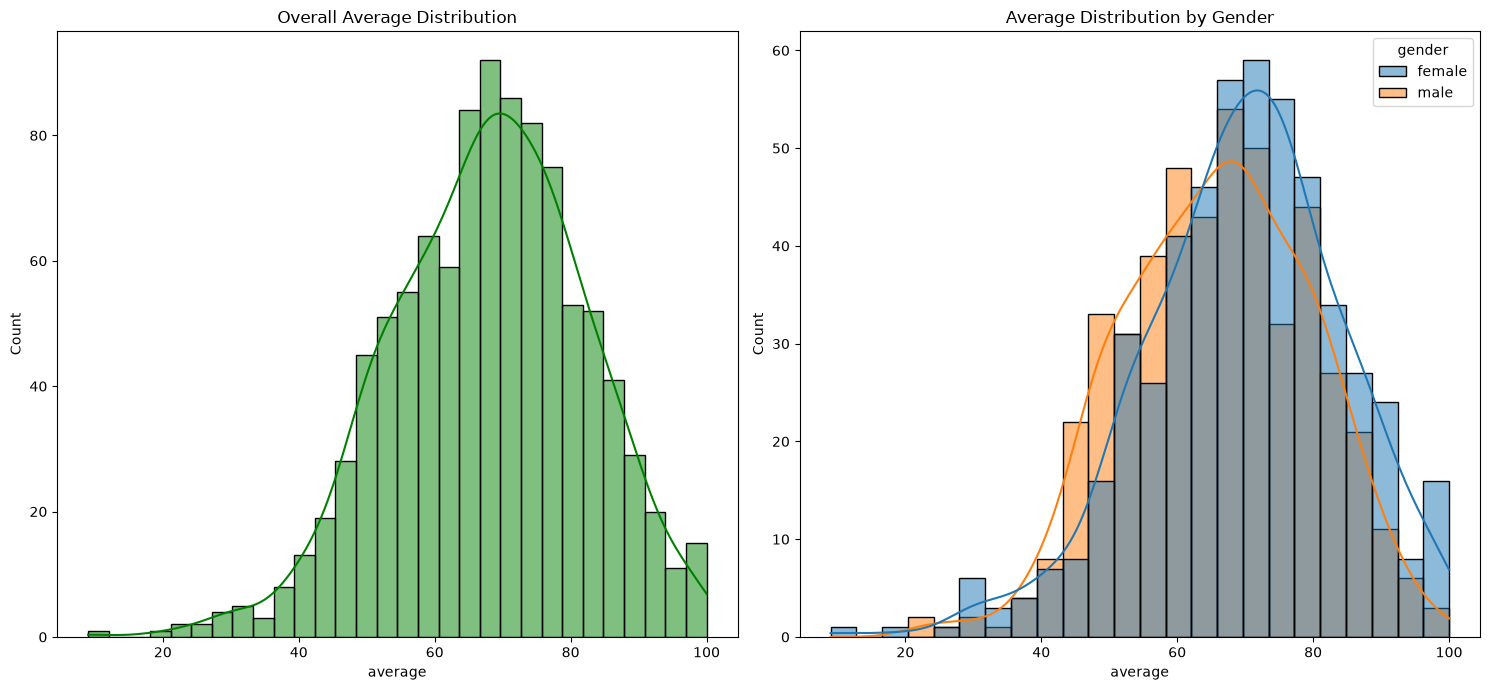

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(15, 7))

# General distribution
sns.histplot(data=df, x='average', bins=30, kde=True, color='g', ax=axs[0])
axs[0].set_title('Overall Average Distribution')

# Distribution by gender
sns.histplot(data=df, x='average', kde=True, hue='gender', ax=axs[1])
axs[1].set_title('Average Distribution by Gender')

plt.tight_layout()
plt.show()

#####  Insights
- Female students tend to perform better than male students.

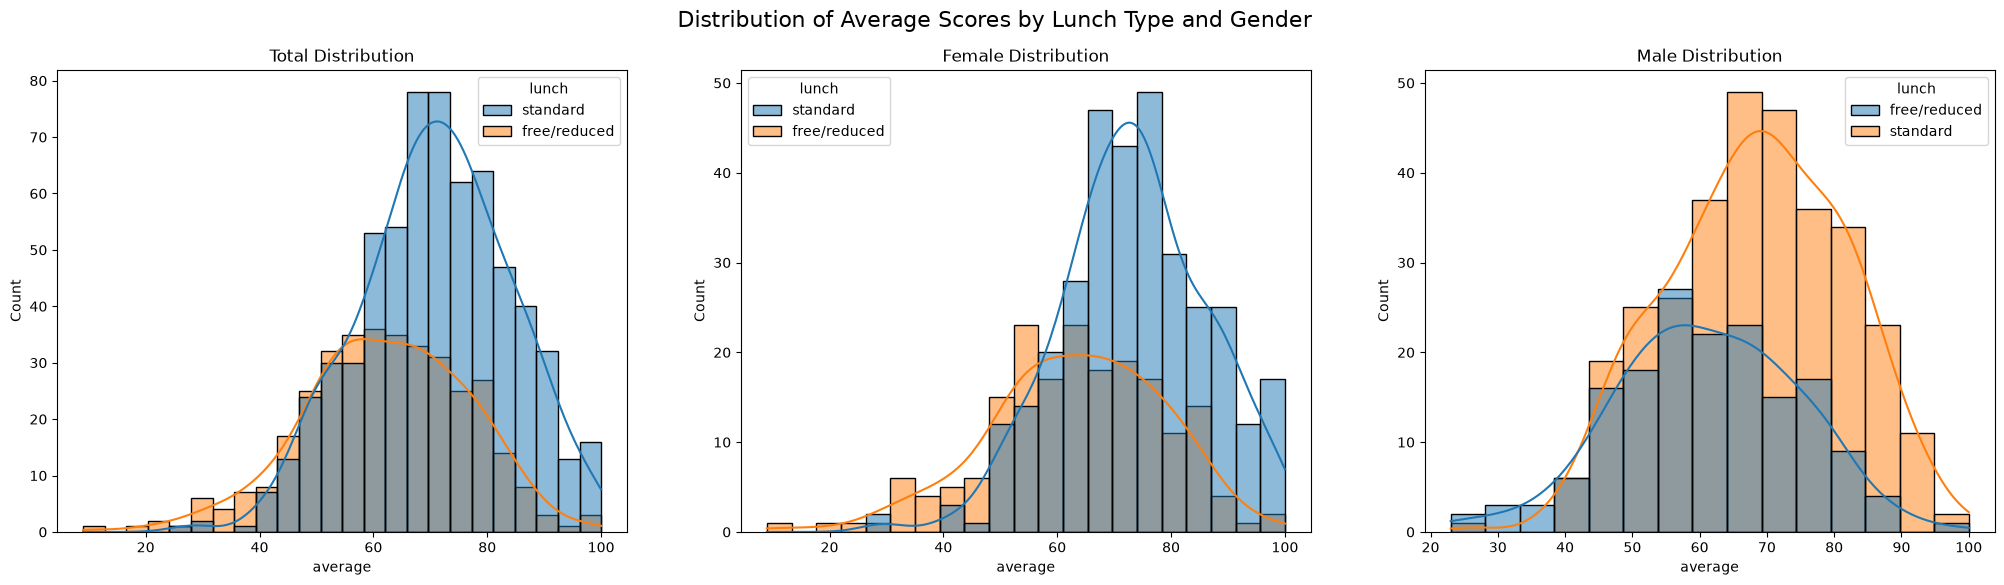

In [15]:
plt.subplots(1, 3, figsize=(25, 6))

plt.subplot(131)
sns.histplot(data=df, x='average', kde=True, hue='lunch')
plt.title('Total Distribution')

plt.subplot(132)
sns.histplot(data=df[df.gender == 'female'], x='average', kde=True, hue='lunch')
plt.title('Female Distribution')

plt.subplot(133)
sns.histplot(data=df[df.gender == 'male'], x='average', kde=True, hue='lunch')
plt.title('Male Distribution')

# Título general para todo el trío
plt.suptitle('Distribution of Average Scores by Lunch Type and Gender', fontsize=16)
plt.show()

#####  Insights
- Standard lunch helps perform well in exams.
- Standard lunch helps perform well in exams be it a male or a female.

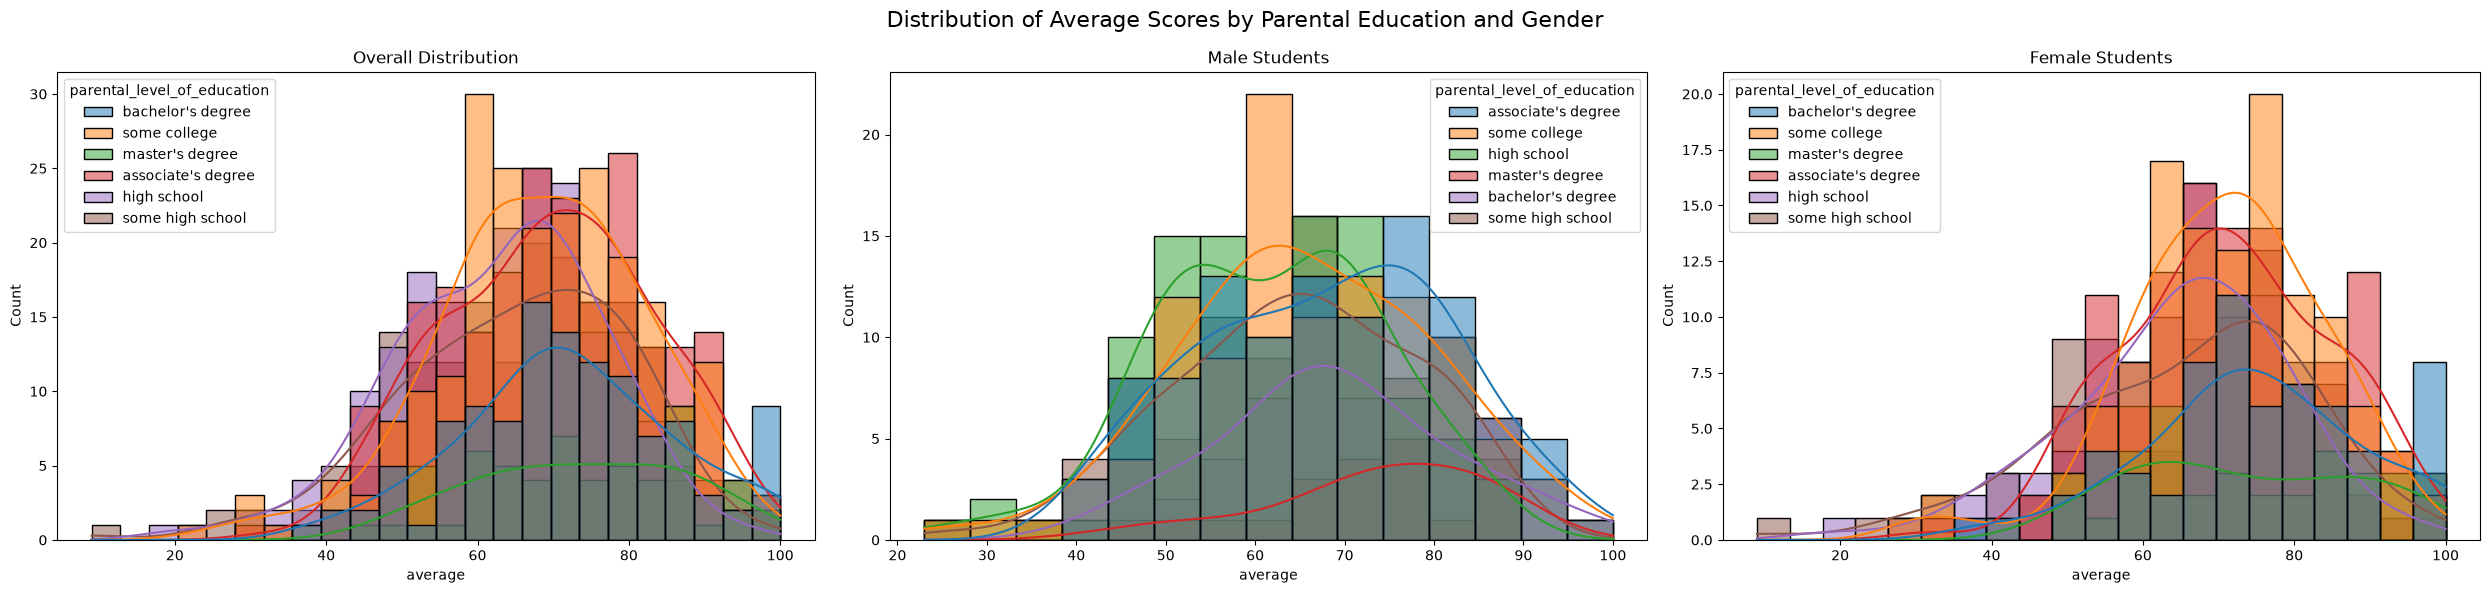

In [16]:
fig, axs = plt.subplots(1, 3, figsize=(25, 6))

# Plot 1: Overall population distribution by parental level of education
sns.histplot(data=df, x='average', kde=True, hue='parental_level_of_education', ax=axs[0])
axs[0].set_title('Overall Distribution')

# Plot 2: Male students distribution by parental level of education
sns.histplot(data=df[df.gender == 'male'], x='average', kde=True, hue='parental_level_of_education', ax=axs[1])
axs[1].set_title('Male Students')

# Plot 3: Female students distribution by parental level of education
sns.histplot(data=df[df.gender == 'female'], x='average', kde=True, hue='parental_level_of_education', ax=axs[2])
axs[2].set_title('Female Students')

# Add overall title and optimize layout
plt.suptitle('Distribution of Average Scores by Parental Education and Gender', fontsize=16)
plt.tight_layout()
plt.show()

#####  Insights
- In general parent's education doesn't affect students' performance.
- 2nd plot shows that parents whose education is of associate's degree or master's degree their male child tends to perform well in his exams.
- In the 3rd plot we can see there is no effect from parent's education on female students.

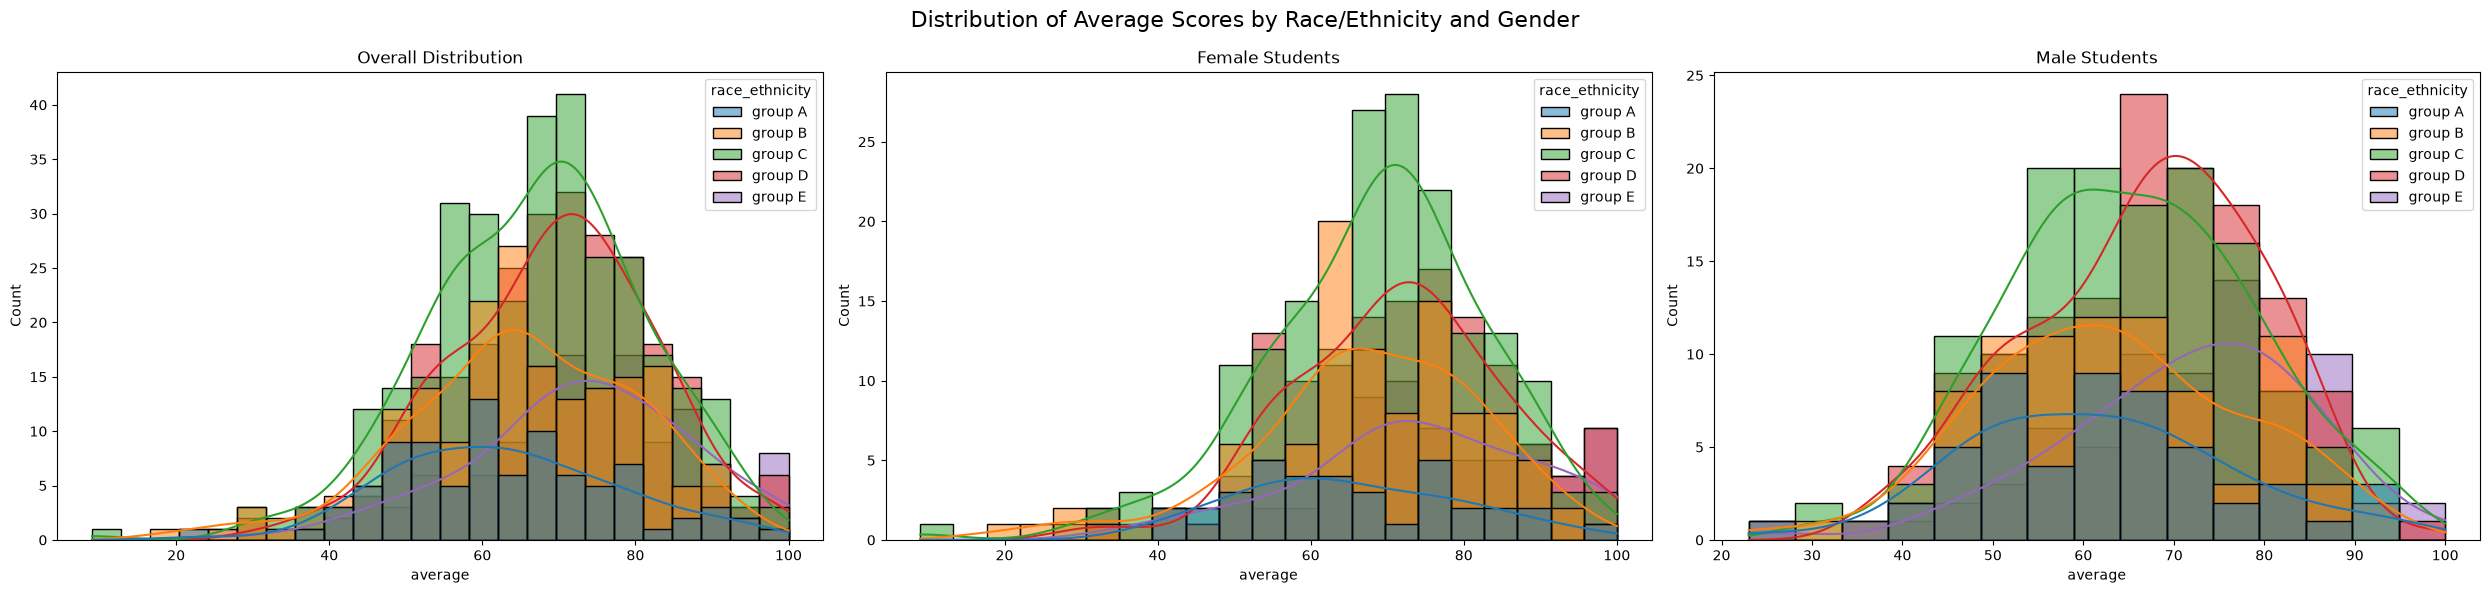

In [17]:
fig, axs = plt.subplots(1, 3, figsize=(25, 6))

# Plot 1: Overall population distribution by race/ethnicity
sns.histplot(data=df, x='average', kde=True, hue='race_ethnicity', hue_order=sorted(df['race_ethnicity'].dropna().unique()), ax=axs[0])
axs[0].set_title('Overall Distribution')

# Plot 2: Female students distribution by race/ethnicity
sns.histplot(data=df[df.gender == 'female'], x='average', kde=True, hue='race_ethnicity', hue_order=sorted(df['race_ethnicity'].dropna().unique()), ax=axs[1])
axs[1].set_title('Female Students')

# Plot 3: Male students distribution by race/ethnicity
sns.histplot(data=df[df.gender == 'male'], x='average', kde=True, hue='race_ethnicity', hue_order=sorted(df['race_ethnicity'].dropna().unique()), ax=axs[2])
axs[2].set_title('Male Students')

# Add overall title and optimize layout
plt.suptitle('Distribution of Average Scores by Race/Ethnicity and Gender', fontsize=16)
plt.tight_layout()
plt.show()

#####  Insights
- Students of group A and group B tend to perform poorly in exams.
- Students of group A and group B tend to perform poorly in exam irrespective of whether they are male or female

#### 4.2 Maximumum score of students in all three subjects

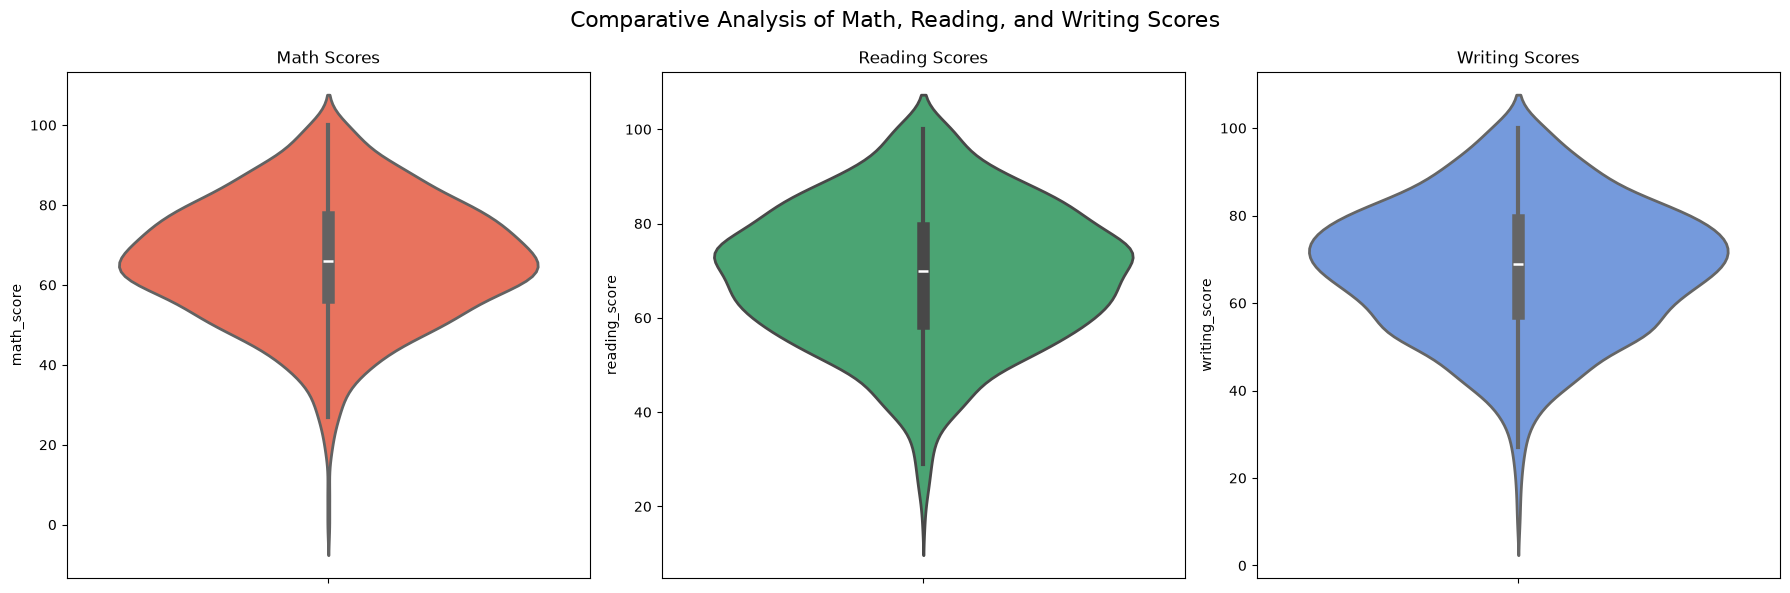

In [18]:
fig, axs = plt.subplots(1, 3, figsize=(18, 6))

# Plot 1: Math scores distribution and variance
sns.violinplot(y='math_score', data=df, color='tomato', linewidth=2, ax=axs[0])
axs[0].set_title('Math Scores')

# Plot 2: Reading scores distribution and variance
sns.violinplot(y='reading_score', data=df, color='mediumseagreen', linewidth=2, ax=axs[1])
axs[1].set_title('Reading Scores')

# Plot 3: Writing scores distribution and variance
sns.violinplot(y='writing_score', data=df, color='cornflowerblue', linewidth=2, ax=axs[2])
axs[2].set_title('Writing Scores')

plt.suptitle('Comparative Analysis of Math, Reading, and Writing Scores', fontsize=16)
plt.tight_layout()
plt.show()

#### Insights
- From the above three plots its clearly visible that most of the students score in between 60-80 in Maths whereas in reading and writing most of them score from 50-80

#### 4.3 Multivariate analysis using pyplot

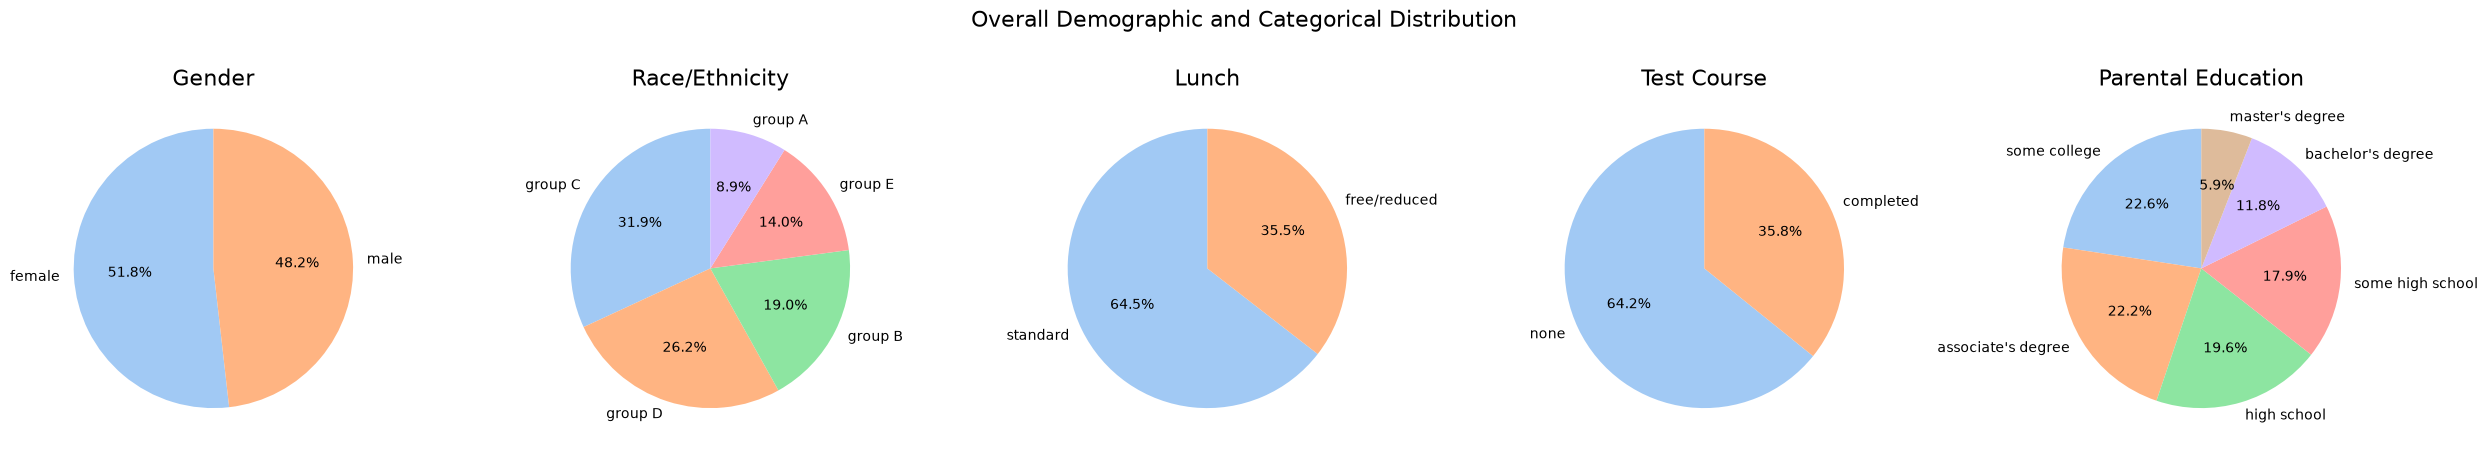

In [19]:
fig, axs = plt.subplots(1, 5, figsize=(25, 5))

# Plot 1: Gender distribution
gender_counts = df['gender'].value_counts()
axs[0].pie(gender_counts, labels=gender_counts.index, colors=sns.color_palette('pastel'), autopct='%1.1f%%', startangle=90)
axs[0].set_title('Gender', fontsize=16)

# Plot 2: Race/Ethnicity distribution
race_counts = df['race_ethnicity'].value_counts()
axs[1].pie(race_counts, labels=race_counts.index, colors=sns.color_palette('pastel'), autopct='%1.1f%%', startangle=90)
axs[1].set_title('Race/Ethnicity', fontsize=16)

# Plot 3: Lunch type distribution
lunch_counts = df['lunch'].value_counts()
axs[2].pie(lunch_counts, labels=lunch_counts.index, colors=sns.color_palette('pastel'), autopct='%1.1f%%', startangle=90)
axs[2].set_title('Lunch', fontsize=16)

# Plot 4: Test preparation course status
prep_counts = df['test_preparation_course'].value_counts()
axs[3].pie(prep_counts, labels=prep_counts.index, colors=sns.color_palette('pastel'), autopct='%1.1f%%', startangle=90)
axs[3].set_title('Test Course', fontsize=16)

# Plot 5: Parental level of education distribution
edu_counts = df['parental_level_of_education'].value_counts()
axs[4].pie(edu_counts, labels=edu_counts.index, colors=sns.color_palette('pastel'), autopct='%1.1f%%', startangle=90)
axs[4].set_title('Parental Education', fontsize=16)

plt.suptitle('Overall Demographic and Categorical Distribution', fontsize=16)
plt.tight_layout()
plt.show()

#####  Insights
- Number of Male and Female students is almost equal
- Number students are greatest in Group C
- Number of students who have standard lunch are greater
- Number of students who have not enrolled in any test preparation course is greater
- Number of students whose parental education is "Some College" is greater followed closely by "Associate's Degree"

#### 4.4 Feature Wise Visualization
#### 4.4.1 GENDER COLUMN
- How is distribution of Gender ?
- Is gender has any impact on student's performance ?

#### UNIVARIATE ANALYSIS ( How is distribution of Gender ? )

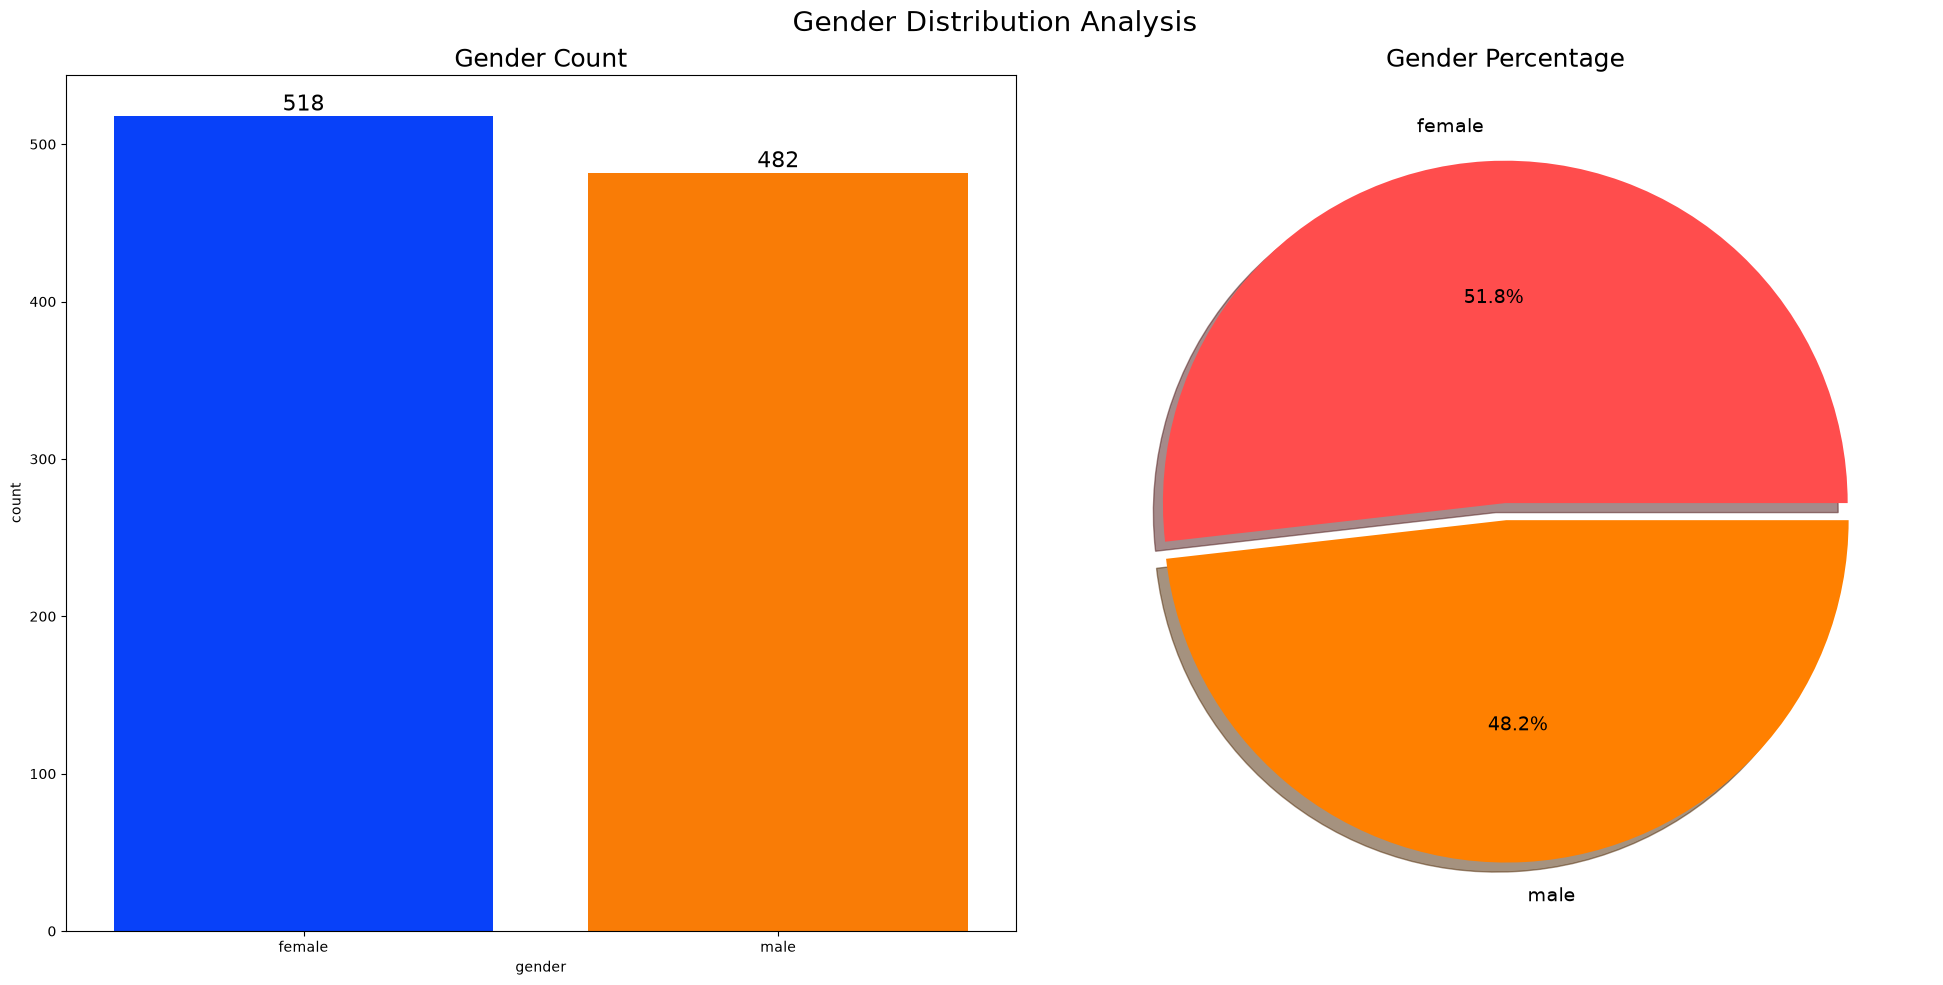

In [20]:
fig, axs = plt.subplots(1, 2, figsize=(20, 10))

# Plot 1: Count plot for gender distribution
sns.countplot(x='gender', data=df, palette='bright', ax=axs[0], saturation=0.95)
axs[0].set_title('Gender Count', fontsize=18)
for container in axs[0].containers:
    axs[0].bar_label(container, color='black', size=16)

# Plot 2: Pie chart for gender percentage distribution
gender_counts = df['gender'].value_counts()
axs[1].pie(
    x=gender_counts, 
    labels=gender_counts.index, 
    explode=[0, 0.05], 
    autopct='%1.1f%%', 
    shadow=True, 
    colors=['#ff4d4d', '#ff8000'],
    textprops={'fontsize': 14}
)
axs[1].set_title('Gender Percentage', fontsize=18)

plt.suptitle('Gender Distribution Analysis', fontsize=20)
plt.tight_layout()
plt.show()

#### Insights 
- Gender has balanced data with female students are 518 (48%) and male students are 482 (52%) 

#### BIVARIATE ANALYSIS ( Is gender has any impact on student's performance ? ) 

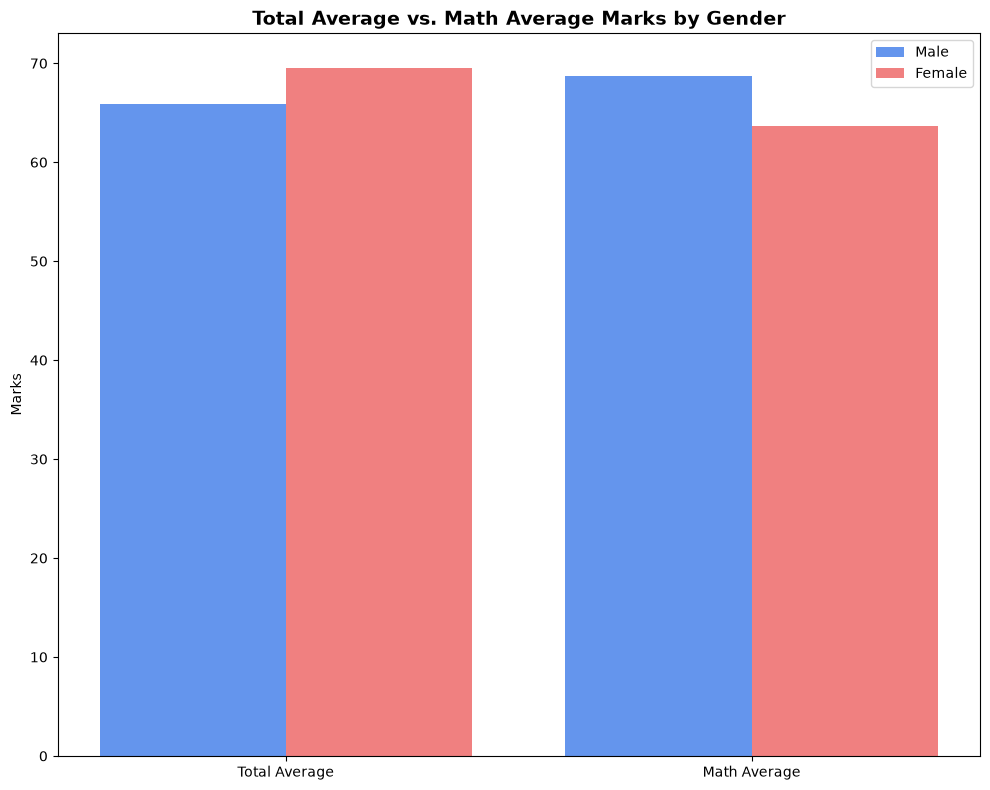

In [21]:
# Group by gender and compute the mean of numeric columns
gender_group = df.groupby('gender').mean(numeric_only=True)

# Set up the figure and axis
fig, ax = plt.subplots(figsize=(10, 8))

X = ['Total Average', 'Math Average']

# Extract values dynamically
# Note: index 0 = female, index 1 = male (if sorted alphabetically or ordered)
female_scores = [gender_group.loc['female', 'average'], gender_group.loc['female', 'math_score']]
male_scores = [gender_group.loc['male', 'average'], gender_group.loc['male', 'math_score']]

X_axis = np.arange(len(X))

# Plot bars for male and female scores
ax.bar(X_axis - 0.2, male_scores, 0.4, label='Male', color='cornflowerblue')
ax.bar(X_axis + 0.2, female_scores, 0.4, label='Female', color='lightcoral')

# Configure axes, labels, and title
ax.set_xticks(X_axis)
ax.set_xticklabels(X)
ax.set_ylabel('Marks')
ax.set_title('Total Average vs. Math Average Marks by Gender', fontweight='bold', fontsize=14)
ax.legend()

plt.tight_layout()
plt.show()

#### Insights 
- On an average females have a better overall score than men.
- whereas males have scored higher in Maths.

#### 4.4.2 RACE/EHNICITY COLUMN
- How is Group wise distribution ?
- Is Race/Ehnicity has any impact on student's performance ?

#### UNIVARIATE ANALYSIS ( How is Group wise distribution ?)

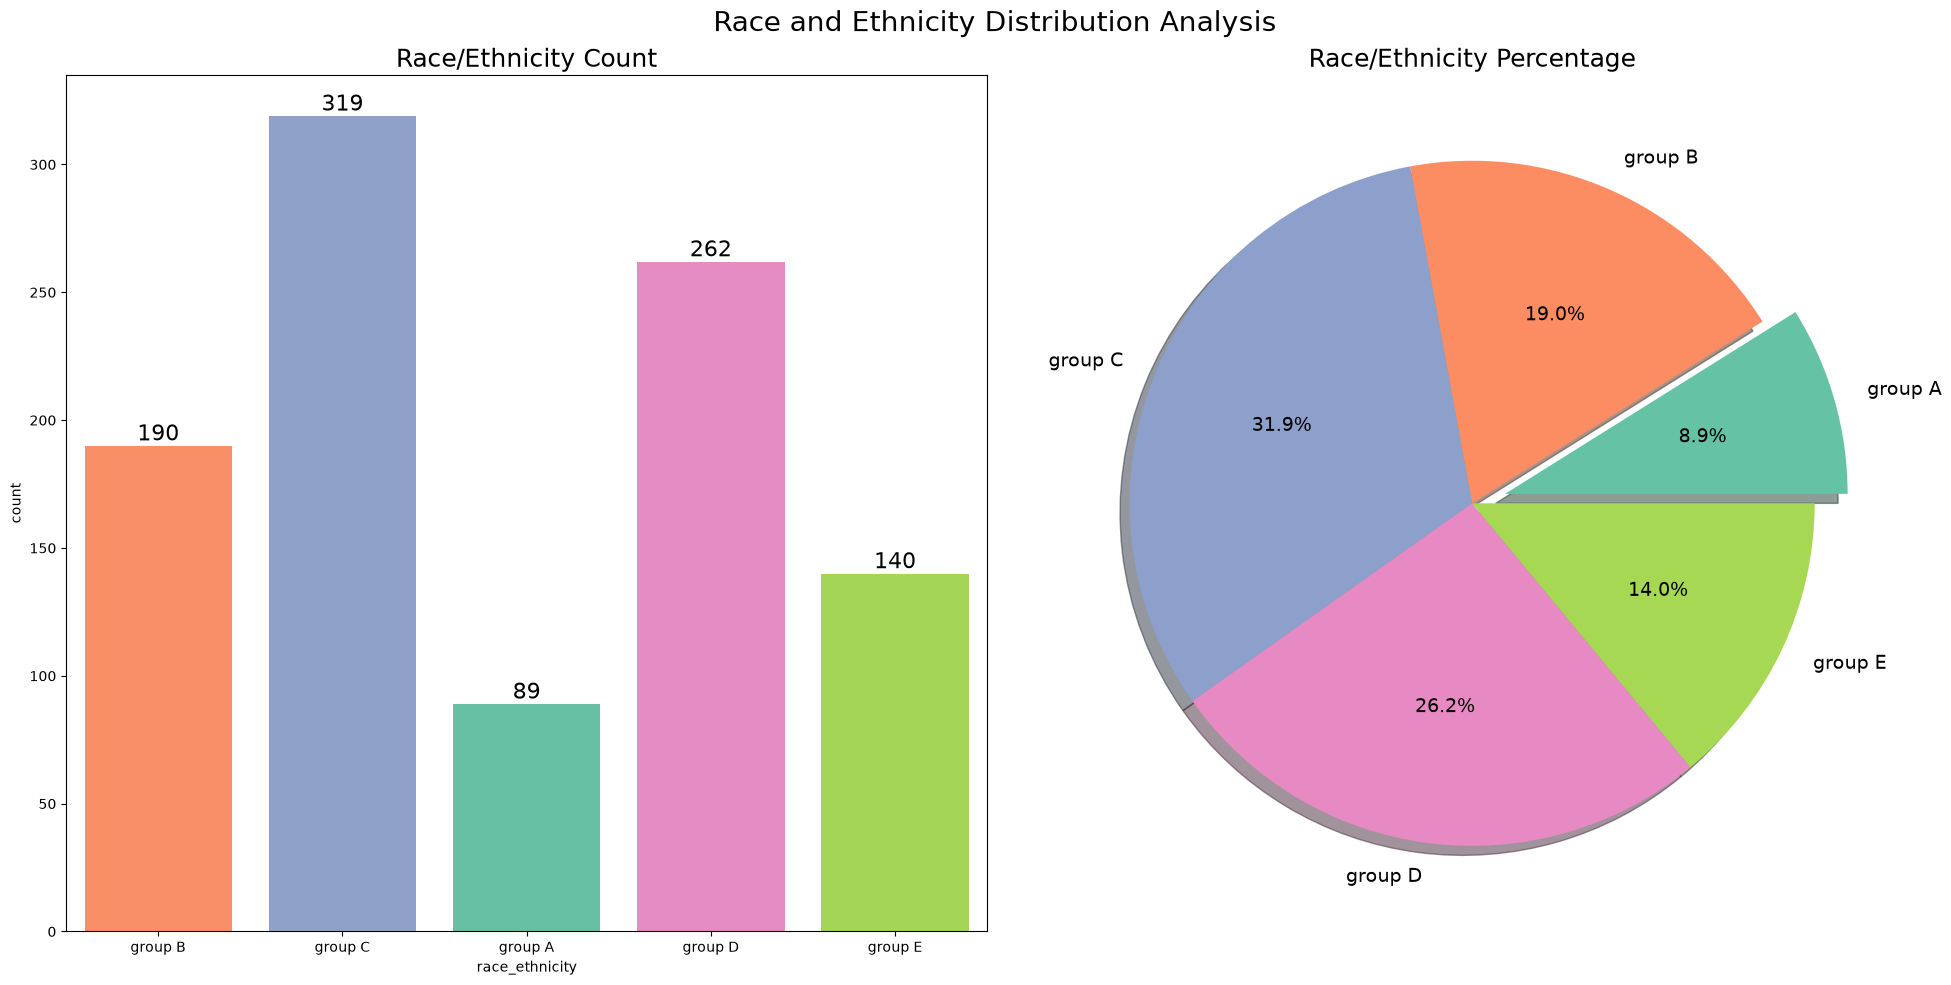

In [22]:
# Create a consistent color mapping for each race/ethnicity group
categories = sorted(df['race_ethnicity'].dropna().unique())
color_palette = sns.color_palette('Set2', len(categories))
palette_dict = dict(zip(categories, color_palette))

fig, axs = plt.subplots(1, 2, figsize=(20, 10))

# Plot 1: Count plot for race/ethnicity distribution
# We map the category colors to the bars using hue and palette
sns.countplot(
    x='race_ethnicity', 
    data=df, 
    hue='race_ethnicity',
    palette=palette_dict, 
    legend=False,
    ax=axs[0], 
    saturation=0.95
)
axs[0].set_title('Race/Ethnicity Count', fontsize=18)
for container in axs[0].containers:
    axs[0].bar_label(container, color='black', size=16)

# Plot 2: Pie chart using the exact same colors assigned by category
race_counts = df['race_ethnicity'].value_counts().sort_index()
# Map colors to match the sorted index order
pie_colors = [palette_dict[cat] for cat in race_counts.index]

axs[1].pie(
    x=race_counts, 
    labels=race_counts.index, 
    explode=[0.1, 0, 0, 0, 0], 
    autopct='%1.1f%%', 
    shadow=True, 
    colors=pie_colors,
    textprops={'fontsize': 14}
)
axs[1].set_title('Race/Ethnicity Percentage', fontsize=18)

plt.suptitle('Race and Ethnicity Distribution Analysis', fontsize=20)
plt.tight_layout()
plt.show()   

#### Insights 
- Most of the student belonging from group C /group D.
- Lowest number of students belong to groupA.

#### BIVARIATE ANALYSIS ( Is Race/Ehnicity has any impact on student's performance ? )

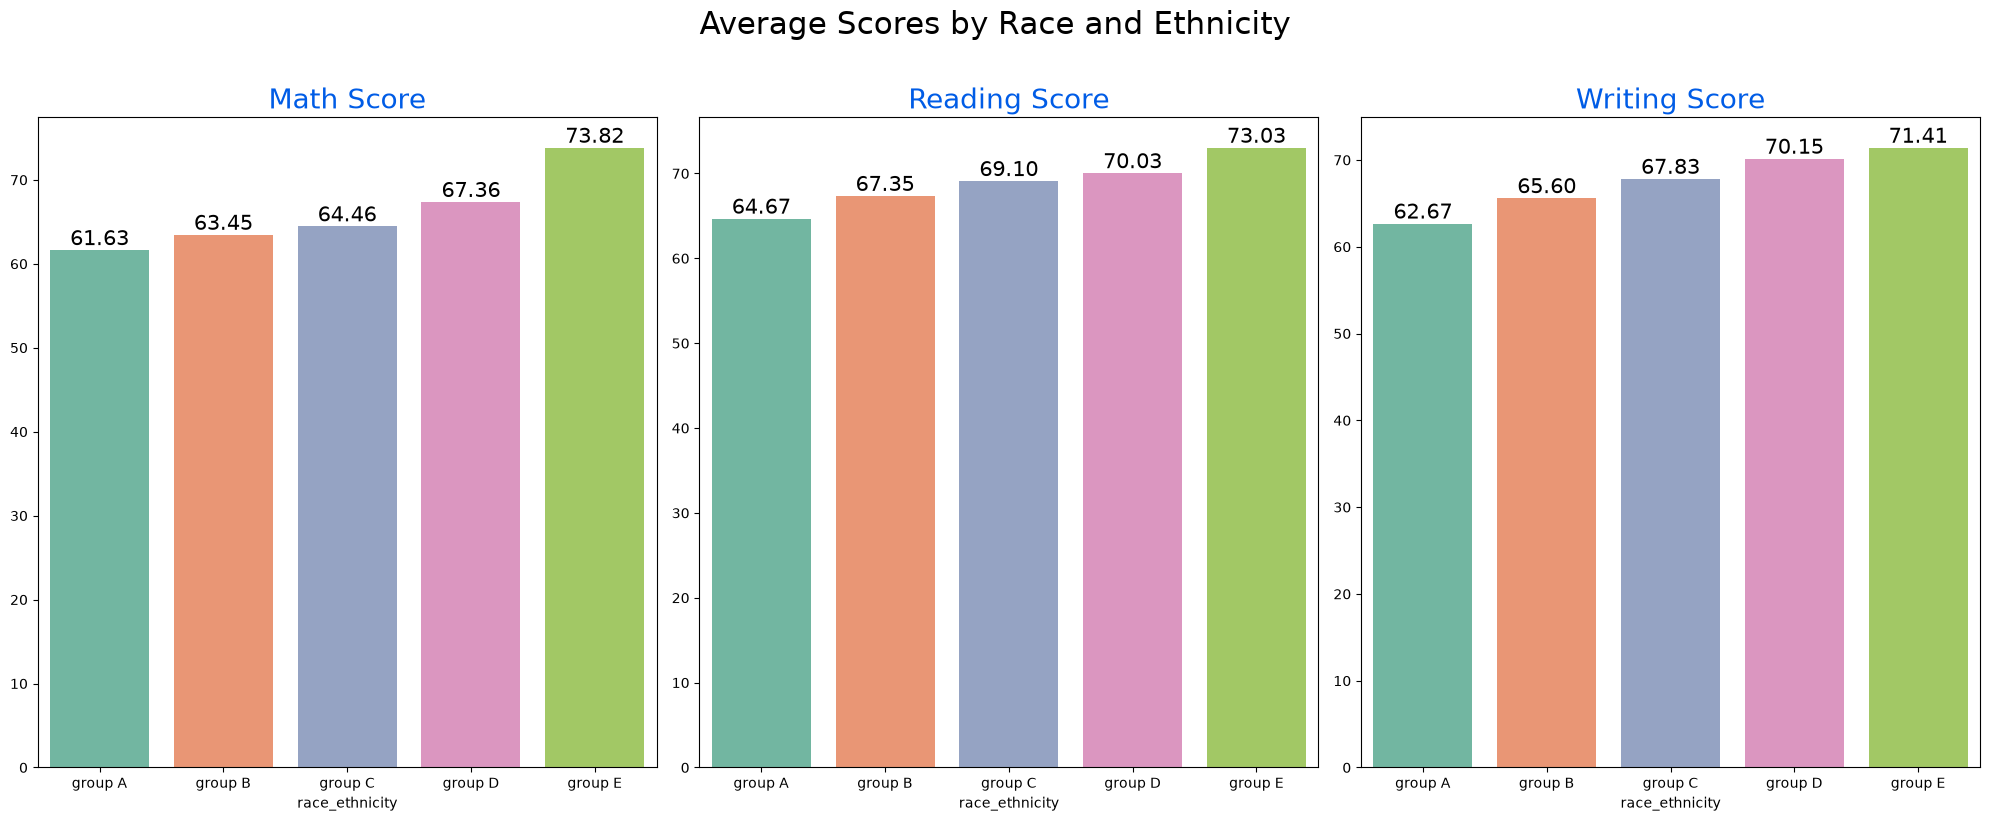

In [23]:
# Group data by race/ethnicity
group_data2 = df.groupby('race_ethnicity')

fig, axs = plt.subplots(1, 3, figsize=(20, 8))

# Plot 1: Math score mean by race/ethnicity
sns.barplot(
    x=group_data2['math_score'].mean().index, 
    y=group_data2['math_score'].mean().values, 
    hue=group_data2['math_score'].mean().index,
    palette=palette_dict, 
    legend=False,
    ax=axs[0]
)
axs[0].set_title('Math Score', color='#005ce6', size=20)
for container in axs[0].containers:
    axs[0].bar_label(container, color='black', size=15, fmt='%.2f')

# Plot 2: Reading score mean by race/ethnicity
sns.barplot(
    x=group_data2['reading_score'].mean().index, 
    y=group_data2['reading_score'].mean().values, 
    hue=group_data2['reading_score'].mean().index,
    palette=palette_dict, 
    legend=False,
    ax=axs[1]
)
axs[1].set_title('Reading Score', color='#005ce6', size=20)
for container in axs[1].containers:
    axs[1].bar_label(container, color='black', size=15, fmt='%.2f')

# Plot 3: Writing score mean by race/ethnicity
sns.barplot(
    x=group_data2['writing_score'].mean().index, 
    y=group_data2['writing_score'].mean().values, 
    hue=group_data2['writing_score'].mean().index,
    palette=palette_dict, 
    legend=False,
    ax=axs[2]
)
axs[2].set_title('Writing Score', color='#005ce6', size=20)
for container in axs[2].containers:
    axs[2].bar_label(container, color='black', size=15, fmt='%.2f')

plt.suptitle('Average Scores by Race and Ethnicity', fontsize=22, y=1.02)
plt.tight_layout()
plt.show()

#### Insights 
- Group E students have scored the highest marks. 
- Group A students have scored the lowest marks. 
- Students from a lower Socioeconomic status have a lower avg in all course subjects

#### 4.4.3 PARENTAL LEVEL OF EDUCATION COLUMN
- What is educational background of student's parent ?
- Is parental education has any impact on student's performance ?

#### UNIVARIATE ANALYSIS ( What is educational background of student's parent ? )

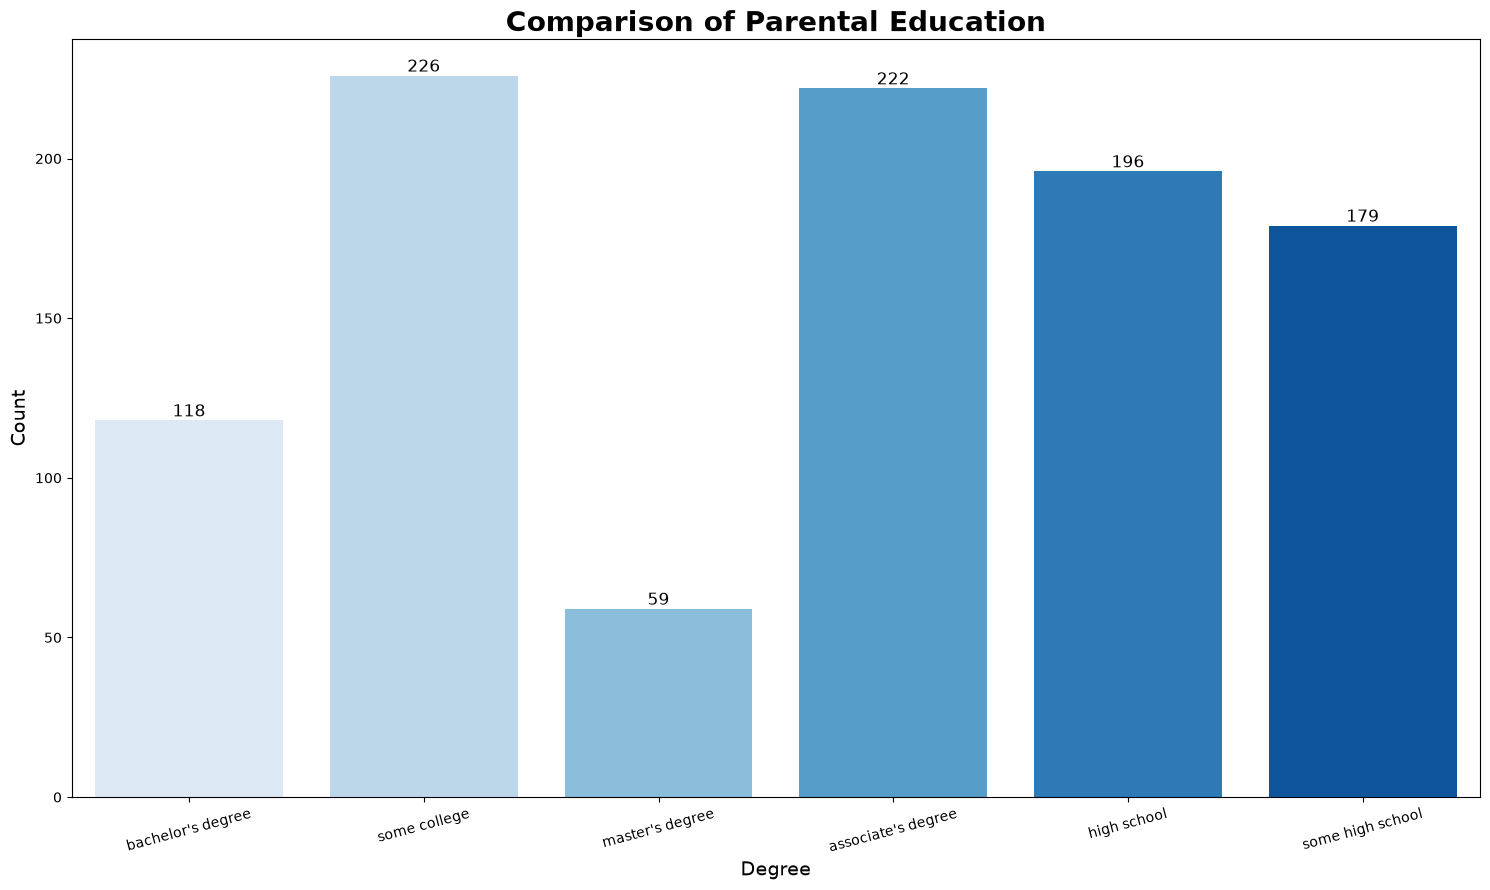

In [24]:
fig, ax = plt.subplots(figsize=(15, 9))

# Plot countplot for parental level of education
sns.countplot(
    data=df, 
    x='parental_level_of_education', 
    hue='parental_level_of_education',
    palette='Blues', 
    legend=False,
    ax=ax, 
    saturation=0.95
)

# Configure titles and labels
ax.set_title('Comparison of Parental Education', fontweight='bold', fontsize=20)
ax.set_xlabel('Degree', fontsize=14)
ax.set_ylabel('Count', fontsize=14)

# Add value labels on top of each bar
for container in ax.containers:
    ax.bar_label(container, color='black', size=12)

# Rotate x-axis labels for better readability
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

#### Insights 
- Largest number of parents are from some college.

#### BIVARIATE ANALYSIS ( Is parental education has any impact on student's performance ? )

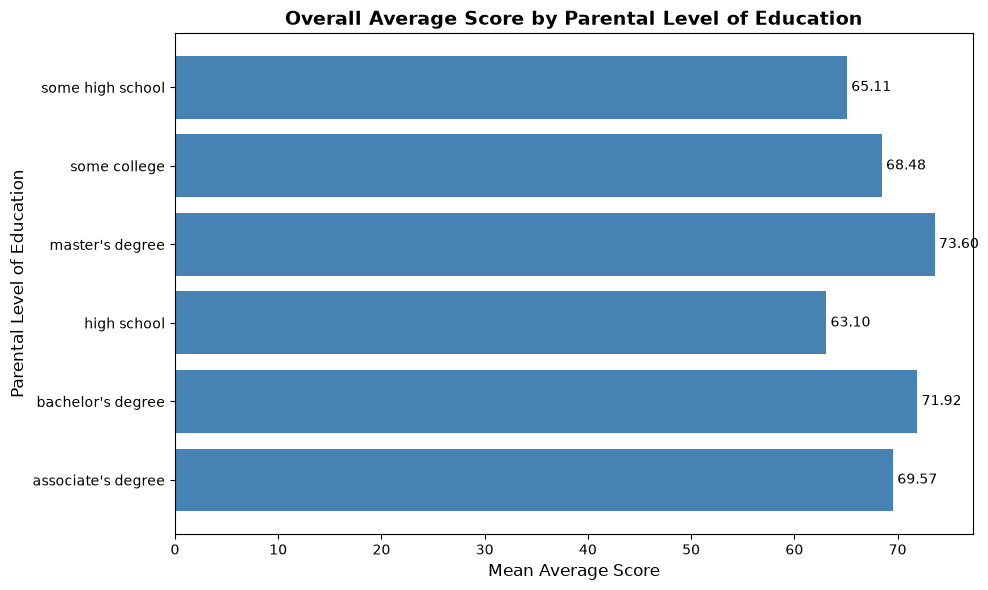

In [25]:
# Group by parental level of education and compute the mean of the average score
parental_edu_group = df.groupby('parental_level_of_education')['average'].mean().reset_index()

# Set up the figure and axis
fig, ax = plt.subplots(figsize=(10, 6))

# Plot horizontal bar chart for the average score
ax.barh(
    parental_edu_group['parental_level_of_education'], 
    parental_edu_group['average'], 
    color='steelblue'
)

# Configure title and labels
ax.set_title('Overall Average Score by Parental Level of Education', fontsize=14, fontweight='bold')
ax.set_xlabel('Mean Average Score', fontsize=12)
ax.set_ylabel('Parental Level of Education', fontsize=12)

# Add values on top of the bars for better readability
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3)

plt.tight_layout()
plt.show()

#### Insights 
- The score of student whose parents possess master and bachelor level education are higher than others.

#### 4.4.4 LUNCH COLUMN 
- Which type of lunch is most common amoung students ?
- What is the effect of lunch type on test results?


#### UNIVARIATE ANALYSIS ( Which type of lunch is most common amoung students ? )

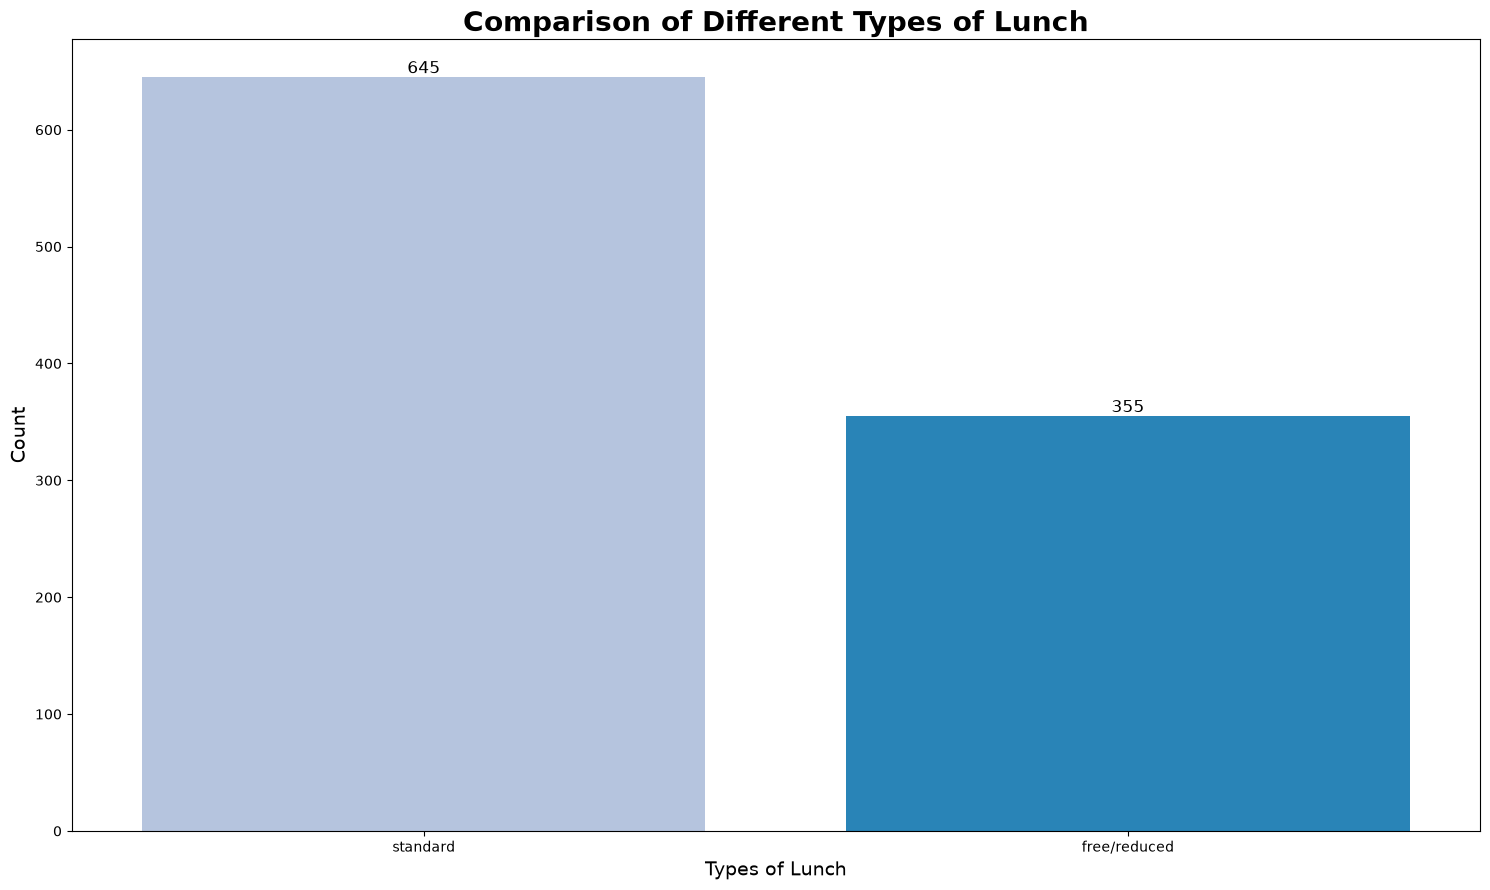

In [26]:
fig, ax = plt.subplots(figsize=(15, 9))

# Plot countplot for lunch distribution
sns.countplot(
    data=df, 
    x='lunch', 
    hue='lunch',
    palette='PuBu', 
    legend=False,
    ax=ax, 
    saturation=0.95
)

# Configure titles and labels
ax.set_title('Comparison of Different Types of Lunch', fontweight='bold', fontsize=20)
ax.set_xlabel('Types of Lunch', fontsize=14)
ax.set_ylabel('Count', fontsize=14)

# Add value labels on top of each bar
for container in ax.containers:
    ax.bar_label(container, color='black', size=12)

plt.tight_layout()
plt.show()

#### Insights 
- Students being served Standard lunch was more than free lunch

#### BIVARIATE ANALYSIS (  Is lunch type intake has any impact on student's performance ? )

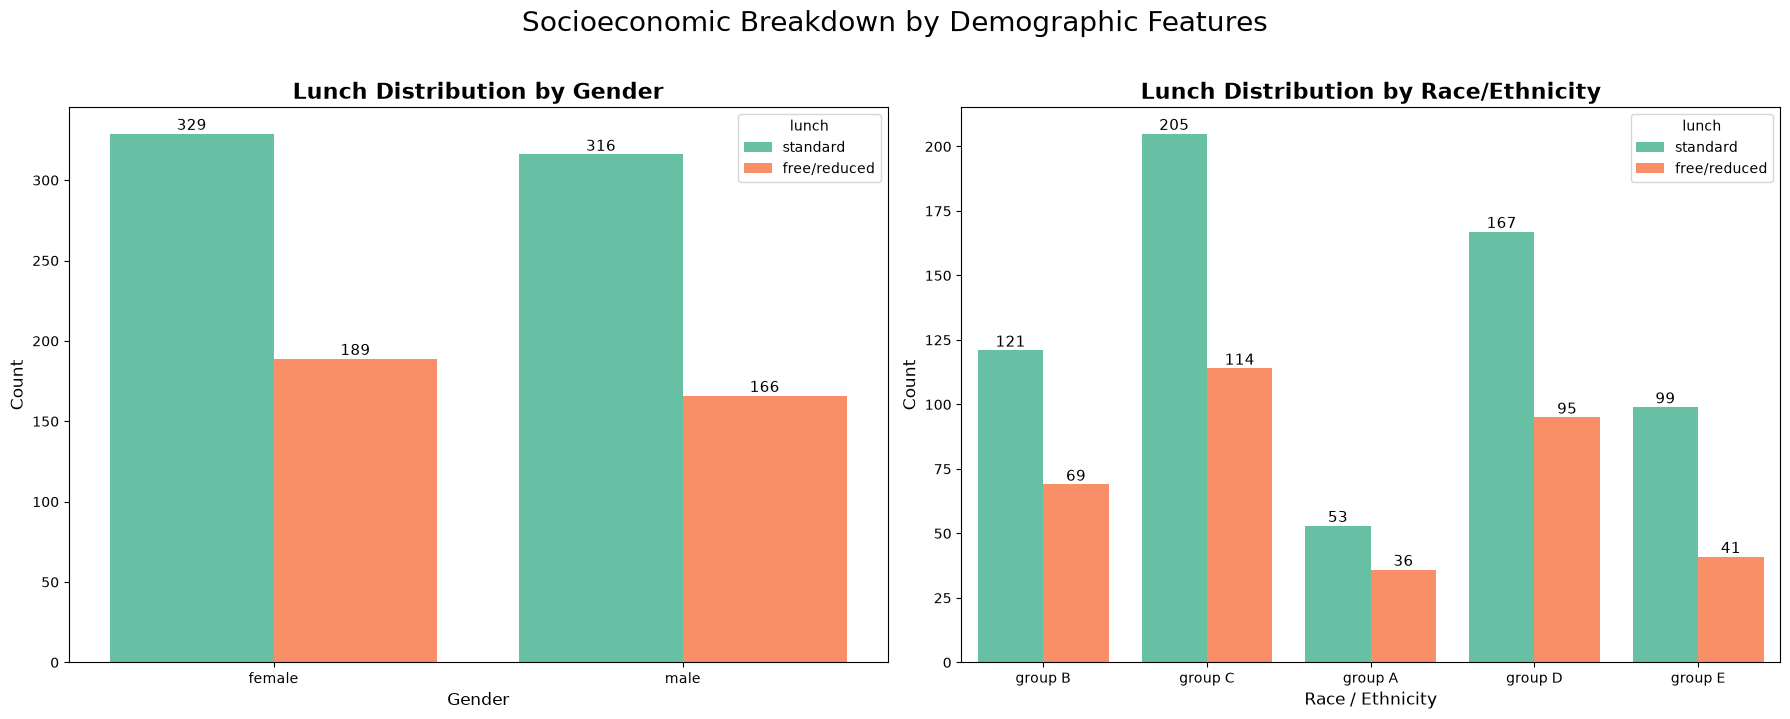

In [27]:
fig, axs = plt.subplots(1, 2, figsize=(18, 7))

# Plot 1: Lunch distribution across genders
sns.countplot(
    data=df,
    x='gender',
    hue='lunch',
    palette='Set2',
    ax=axs[0],
    saturation=0.95
)
axs[0].set_title('Lunch Distribution by Gender', fontsize=16, fontweight='bold')
axs[0].set_xlabel('Gender', fontsize=12)
axs[0].set_ylabel('Count', fontsize=12)
for container in axs[0].containers:
    axs[0].bar_label(container, color='black', size=11)

# Plot 2: Lunch distribution across race/ethnicity
sns.countplot(
    data=df,
    x='race_ethnicity',
    hue='lunch',
    palette='Set2',
    ax=axs[1],
    saturation=0.95
)
axs[1].set_title('Lunch Distribution by Race/Ethnicity', fontsize=16, fontweight='bold')
axs[1].set_xlabel('Race / Ethnicity', fontsize=12)
axs[1].set_ylabel('Count', fontsize=12)
for container in axs[1].containers:
    axs[1].bar_label(container, color='black', size=11)

plt.suptitle('Socioeconomic Breakdown by Demographic Features', fontsize=20, y=1.02)
plt.tight_layout()
plt.show()

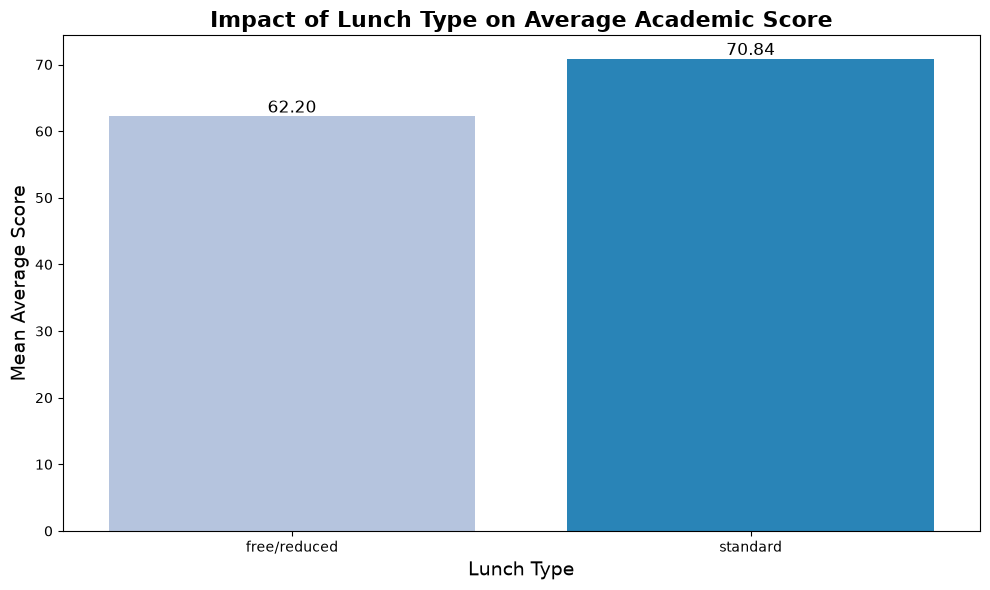

In [28]:
# Group data by lunch type and compute the mean of the average score
lunch_group = df.groupby('lunch')['average'].mean().reset_index()

# Set up the figure and axis
fig, ax = plt.subplots(figsize=(10, 6))

# Plot bar chart for lunch type vs average score
sns.barplot(
    data=lunch_group,
    x='lunch',
    y='average',
    hue='lunch',
    palette='PuBu',
    legend=False,
    ax=ax,
    saturation=0.95
)

# Configure titles and labels
ax.set_title('Impact of Lunch Type on Average Academic Score', fontsize=16, fontweight='bold')
ax.set_xlabel('Lunch Type', fontsize=14)
ax.set_ylabel('Mean Average Score', fontsize=14)

# Add value labels on top of each bar
for container in ax.containers:
    ax.bar_label(container, color='black', size=12, fmt='%.2f')

plt.tight_layout()
plt.show()

#### Insights 
- Students who get Standard Lunch tend to perform better than students who got free/reduced lunch

#### 4.4.5 TEST PREPARATION COURSE COLUMN 
- Which type of test preparation is most common amoung students ?
- Is Test prepration course has any impact on student's performance ?

#### UNIVARIATE ANALYSIS ( Which type of test preparation is most common amoung students ? )

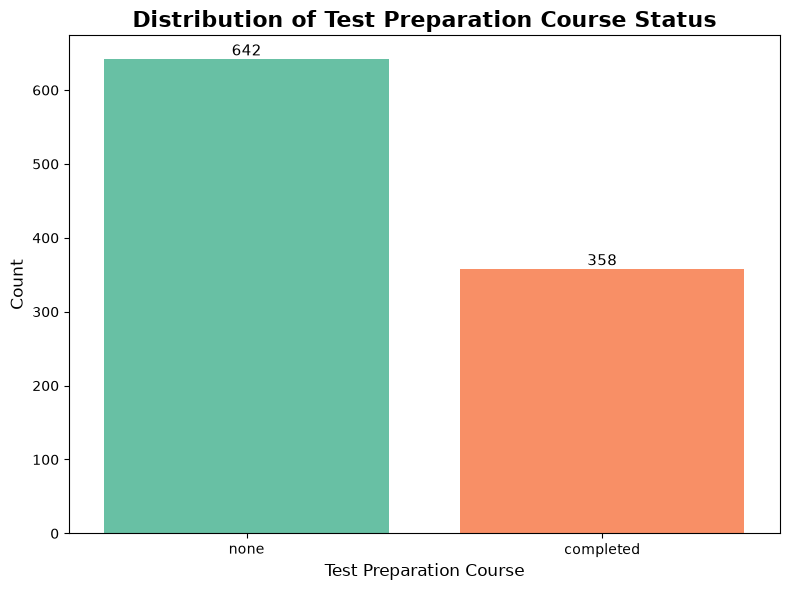

In [29]:
fig, ax = plt.subplots(figsize=(8, 6))

# Plot countplot for test preparation course status
sns.countplot(
    data=df,
    x='test_preparation_course',
    hue='test_preparation_course',
    palette='Set2',
    legend=False,
    ax=ax,
    saturation=0.95
)

# Configure titles and labels
ax.set_title('Distribution of Test Preparation Course Status', fontsize=16, fontweight='bold')
ax.set_xlabel('Test Preparation Course', fontsize=12)
ax.set_ylabel('Count', fontsize=12)

# Add value labels on top of each bar
for container in ax.containers:
    ax.bar_label(container, color='black', size=11)

plt.tight_layout()
plt.show()

#### BIVARIATE ANALYSIS ( Is Test prepration course has any impact on student's performance ? )

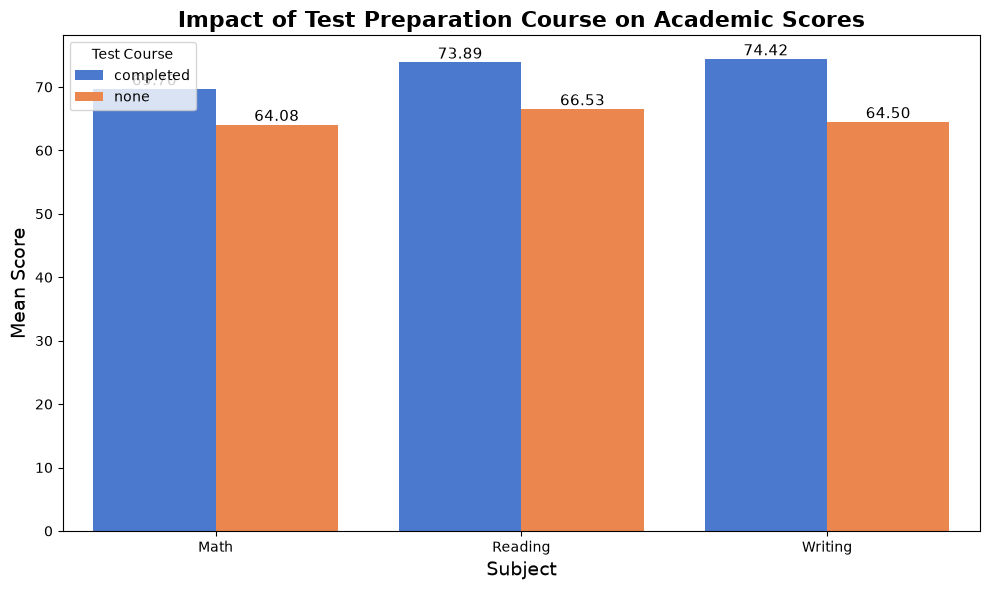

In [30]:
# Group by test preparation course and compute the mean of the score categories
prep_group = df.groupby('test_preparation_course')[['math_score', 'reading_score', 'writing_score']].mean().reset_index()

# Melt the dataframe from wide to long format for Seaborn barplot
prep_melted = prep_group.melt(
    id_vars='test_preparation_course', 
    value_vars=['math_score', 'reading_score', 'writing_score'],
    var_name='subject', 
    value_name='mean_score'
)

# Clean up subject names for better readability in the legend/axis
prep_melted['subject'] = prep_melted['subject'].str.replace('_score', '').str.capitalize()

# Set up the figure and axis
fig, ax = plt.subplots(figsize=(10, 6))

# Plot grouped bar chart comparing scores across subjects by test preparation status
sns.barplot(
    data=prep_melted,
    x='subject',
    y='mean_score',
    hue='test_preparation_course',
    palette='muted',
    ax=ax,
    saturation=0.95
)

# Configure titles, labels, and legend
ax.set_title('Impact of Test Preparation Course on Academic Scores', fontsize=16, fontweight='bold')
ax.set_xlabel('Subject', fontsize=14)
ax.set_ylabel('Mean Score', fontsize=14)
ax.legend(title='Test Course', loc='upper left')

# Add value labels on top of each bar
for container in ax.containers:
    ax.bar_label(container, color='black', size=11, fmt='%.2f')

plt.tight_layout()
plt.show()

#### Insights  
- Students who have completed the Test Prepration Course have scores higher in all three categories than those who haven't taken the course

#### 4.4.6 CHECKING OUTLIERS

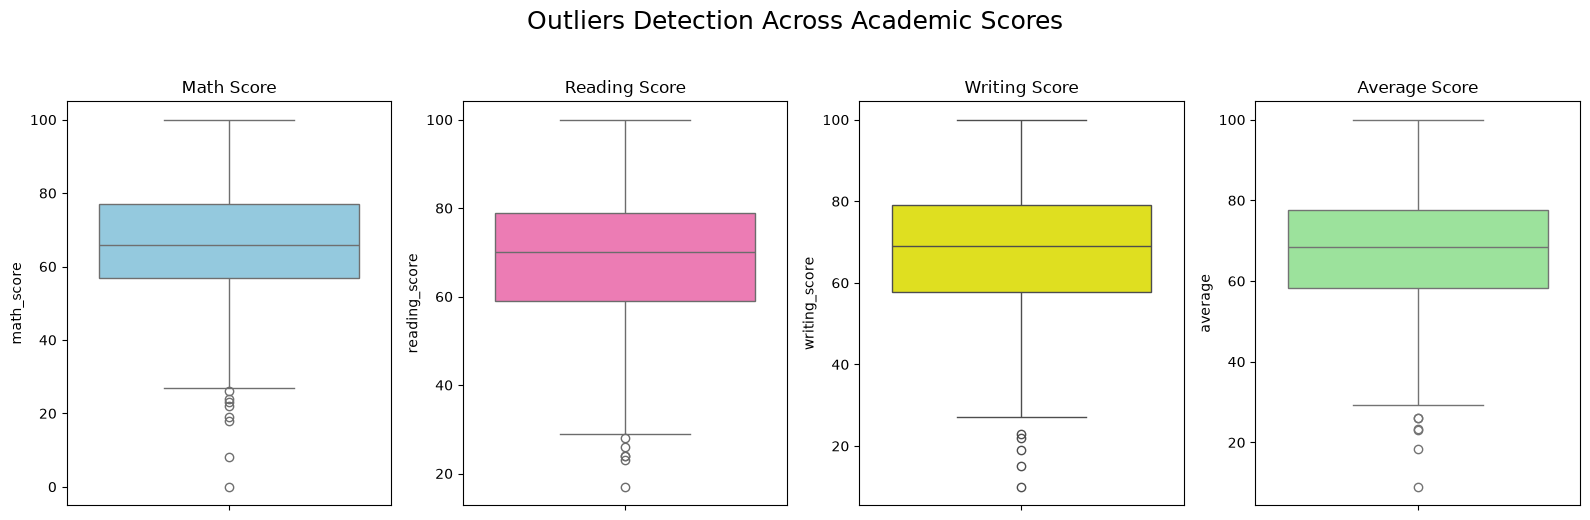

In [31]:
fig, axs = plt.subplots(1, 4, figsize=(16, 5))

# Plot 1: Math score outliers
sns.boxplot(data=df, y='math_score', color='skyblue', ax=axs[0])
axs[0].set_title('Math Score')

# Plot 2: Reading score outliers
sns.boxplot(data=df, y='reading_score', color='hotpink', ax=axs[1])
axs[1].set_title('Reading Score')

# Plot 3: Writing score outliers
sns.boxplot(data=df, y='writing_score', color='yellow', ax=axs[2])
axs[2].set_title('Writing Score')

# Plot 4: Average score outliers
sns.boxplot(data=df, y='average', color='lightgreen', ax=axs[3])
axs[3].set_title('Average Score')

plt.suptitle('Outliers Detection Across Academic Scores', fontsize=18, y=1.03)
plt.tight_layout()
plt.show()

#### 4.4.7 MUTIVARIATE ANALYSIS USING PAIRPLOT

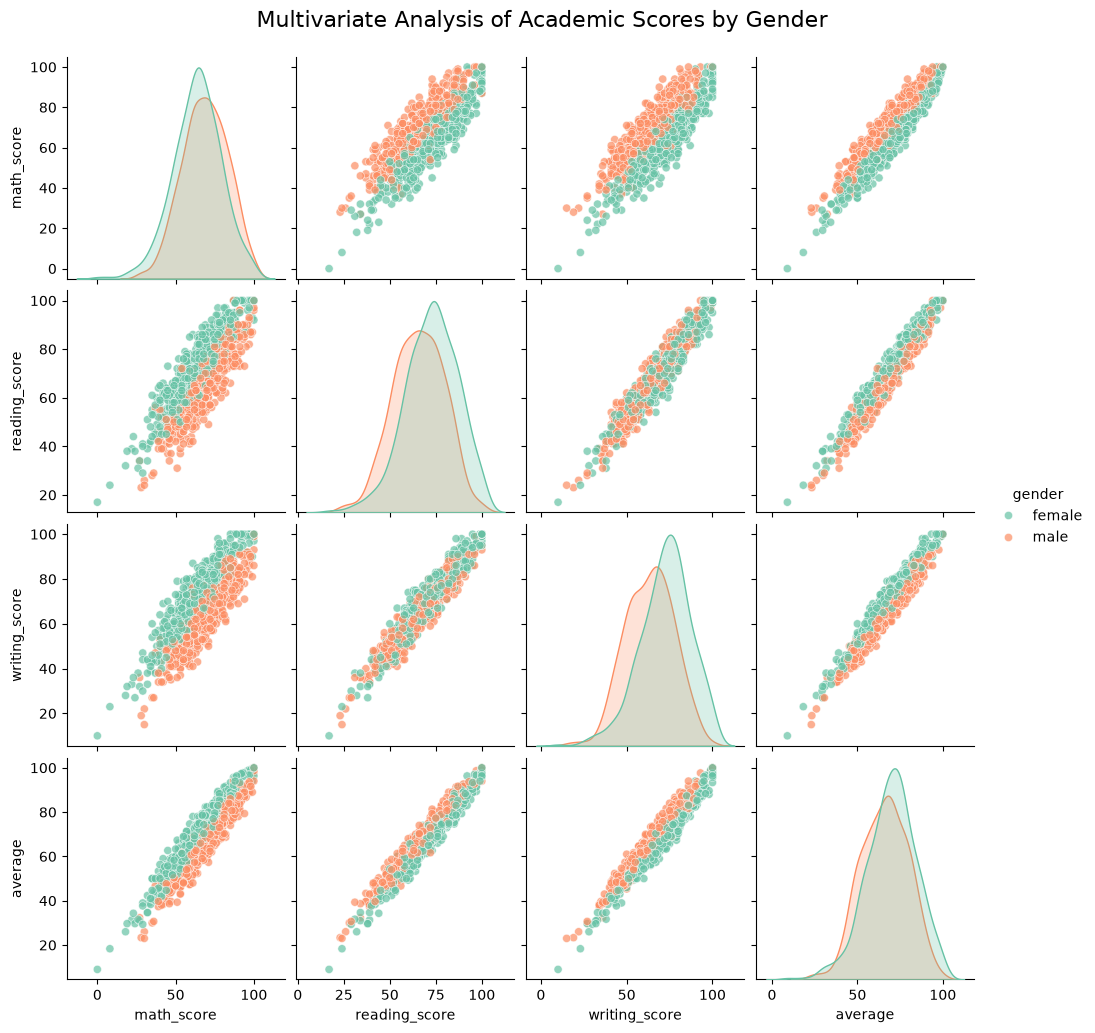

In [32]:
# Create a pairplot for multivariate analysis colored by gender
# We explicitly select the numerical score columns and 'gender' to keep it clean and performant
score_columns = ['math_score', 'reading_score', 'writing_score', 'average', 'gender']

pair_plot = sns.pairplot(
    data=df[score_columns], 
    hue='gender', 
    palette='Set2', 
    diag_kind='kde',
    plot_kws={'alpha': 0.7, 's': 35},
    height=2.5
)

# Grid title
pair_plot.fig.suptitle('Multivariate Analysis of Academic Scores by Gender', fontsize=16, y=1.03)

plt.show()

#### Insights
- From the above plot it is clear that all the scores increase linearly with each other.

### 5. Conclusions
- Student's Performance is related with lunch, race, parental level education
- Females lead in pass percentage and also are top-scorers
- Student's Performance is not much related with test preparation course
- Finishing preparation course is benefitial.